# TP 7 — SVM (machines à vecteurs de support)
**Machine Learning · Apprentissage supervisé · Classification (SVM) et régression (SVR)**

Ce TP reprend les exemples de la présentation (diapos 53 à 57) :

| Exemple | Diapos | Problème |
|---|---|---|
| Exemple 1 | 55 | Classification : un étudiant qui a révisé 5 h va-t-il réussir ? |
| Exemple 2 | 56 | Régression (SVR) : combien coûtera une course de taxi de 5 km ? |

**Objectifs** : calculer **en Python pur** les vecteurs de support, $w$, $b$, la frontière, la marge et la droite du SVR ; vérifier par une recherche exhaustive que ce sont bien les solutions optimales ; puis refaire les mêmes exemples avec **scikit-learn** (`SVC`, `SVR`) et comparer les deux implémentations.

## Rappel de cours (diapos 53 – 54)

**Classification (SVM)** : classes codées $-1 / +1$, fonction $f(x) = w\cdot x + b$, classe prédite = signe de $f(x)$.
- Contrainte pour chaque point : $y_i\,(w\cdot x_i + b) \ge 1$ (chaque point est du bon côté, hors de la marge)
- On cherche la **marge la plus large** $= 2/\|w\|$, c’est-à-dire le **plus petit** $\|w\|$ : $\min \tfrac12\|w\|^2$
- Les **vecteurs de support** sont les points sur le bord de la marge ($y_i f(x_i) = 1$) : ce sont les seuls qui fixent la frontière

**Régression (SVR)** : on entoure la droite d’un **tube** de demi-largeur ε (une tolérance).
- Un point est « dans le tube » si $|y - f(x)| \le \varepsilon$ : pas de pénalité
- Pénalité d’un point hors du tube : $\max(0 ; |y - f(x)| - \varepsilon)$
- Le SVR cherche la droite **la plus plate** (plus petit $|w|$) qui garde les points dans le tube

---
# Partie A — Implémentation from scratch (Python pur)

## Exemple 1 : réussite selon les heures de révision (diapo 55)

| Heures $x$ | 1 | 2 | 6 | 7 |
|---|---|---|---|---|
| Résultat $y$ | échec (−1) | échec (−1) | réussite (+1) | réussite (+1) |

Nouvel étudiant : **5 h** de révision.

In [ ]:
X = [1, 2, 6, 7]
Y = [-1, -1, 1, 1]

### Question 1 — Repérer les vecteurs de support
**Réponse.** En une dimension, la frontière se place entre le plus « fort » des échecs et le plus « faible » des réussites. Les points les plus proches de la frontière sont donc **2 h** (échec) et **6 h** (réussite).

In [ ]:
sv_moins = max(x for x, y in zip(X, Y) if y == -1)   # l'échec le plus proche de l'autre classe
sv_plus = min(x for x, y in zip(X, Y) if y == 1)     # la réussite la plus proche de l'autre classe
print("Vecteurs de support :", sv_moins, "h (échec) et", sv_plus, "h (réussite)")

Vecteurs de support : 2 h (échec) et 6 h (réussite)


### Question 2 — Trouver $w$ et $b$
**Réponse.** Les vecteurs de support sont exactement sur le bord de la marge : $f(2) = -1$ et $f(6) = +1$.
$$w = \frac{1 - (-1)}{6 - 2} = 0{,}5 \qquad b = -1 - w \times 2 = -2$$

In [ ]:
w = (1 - (-1)) / (sv_plus - sv_moins)
b = -1 - w * sv_moins
print(f"w = {w:.4g}")
print(f"b = {b:.4g}")
f = lambda x: w * x + b
print("f(x) pour les 4 étudiants :", [f(x) for x in X])

w = 0.5
b = -2
f(x) pour les 4 étudiants : [-1.5, -1.0, 1.0, 1.5]


### Question 3 — Frontière, marge, contraintes
**Réponse.** Frontière : $f(x) = 0$ → $0{,}5x - 2 = 0$ → $x = 4$ h. Marge $= 2/w = 4$ h. Toutes les contraintes $y_i f(x_i) \ge 1$ sont respectées, avec égalité pour les vecteurs de support.

In [ ]:
frontiere = -b / w
marge = 2 / abs(w)
print(f"frontière (h) = {frontiere:.4g}")
print(f"marge (h) = {marge:.4g}")
for x, y in zip(X, Y):
    print(f"x = {x} h : y·f(x) = {y * f(x):.2f}", "← vecteur de support" if abs(y * f(x) - 1) < 1e-9 else "")
assert all(y * f(x) >= 1 - 1e-9 for x, y in zip(X, Y))

frontière (h) = 4
marge (h) = 4
x = 1 h : y·f(x) = 1.50 
x = 2 h : y·f(x) = 1.00 ← vecteur de support
x = 6 h : y·f(x) = 1.00 ← vecteur de support
x = 7 h : y·f(x) = 1.50 


### Question 4 — Est-ce vraiment la marge maximale ? (vérification par recherche exhaustive)
**Réponse.** On teste un grand nombre de couples $(w, b)$ et on garde, parmi ceux qui respectent toutes les contraintes, celui qui a le **plus petit** $|w|$ (la plus grande marge). Le résultat doit être le même que celui trouvé à la Question 2.

In [ ]:
meilleur = None
for i in range(1, 301):                 # w de 0,01 à 3,00
    w_t = i / 100
    for j in range(-1000, 1):           # b de -10,00 à 0,00
        b_t = j / 100
        if all(y * (w_t * x + b_t) >= 1 - 1e-9 for x, y in zip(X, Y)):
            if meilleur is None or w_t < meilleur[0]:
                meilleur = (w_t, b_t)
print("Plus petit w qui respecte toutes les contraintes :", meilleur)
print(f"w optimal (recherche) = {meilleur[0]:.4g}")
print(f"b optimal (recherche) = {meilleur[1]:.4g}")

Plus petit w qui respecte toutes les contraintes : (0.5, -2.0)
w optimal (recherche) = 0.5
b optimal (recherche) = -2


### Question 5 — Prédire pour l’étudiant de 5 h
**Réponse.** $f(5) = 0{,}5 \times 5 - 2 = 0{,}5 > 0$ → **+1 : réussite**.

In [ ]:
print(f"f(5) = {f(5):.4g}")
print("Étudiant de 5 h →", "réussite (+1)" if f(5) > 0 else "échec (−1)")

f(5) = 0.5
Étudiant de 5 h → réussite (+1)


## Exemple 2 : SVR, prix d’une course de taxi (diapo 56)

| Distance $x$ (km) | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| Prix $y$ (TND) | 2,0 | 3,8 | 4,0 | 5,0 |

Tolérance : $\varepsilon = 0{,}5$ TND. Question : prix d’une course de **5 km** ?

In [ ]:
Xk = [1, 2, 3, 4]
Yk = [2.0, 3.8, 4.0, 5.0]
eps = 0.5

def penalite(y, y_pred, eps):
    return max(0.0, abs(y - y_pred) - eps)

### Question 6 — Tester une droite d’essai $f(x) = x + 1$
**Réponse.** Écarts : 0 ; 0,8 ; 0 ; 0. La course de 2 km sort du tube : $|3{,}8 - 3| = 0{,}8 > 0{,}5$, pénalité $= 0{,}8 - 0{,}5 = 0{,}3$.

In [ ]:
essai = lambda x: x + 1
for x, y in zip(Xk, Yk):
    e = abs(y - essai(x))
    print(f"{x} km : écart = {e:.1f} → {'dans le tube' if e <= eps else 'HORS du tube'} ; pénalité = {penalite(y, essai(x), eps):.1f}")
print(f"pénalité de la course de 2 km = {penalite(3.8, essai(2), eps):.4g}")

1 km : écart = 0.0 → dans le tube ; pénalité = 0.0
2 km : écart = 0.8 → HORS du tube ; pénalité = 0.3
3 km : écart = 0.0 → dans le tube ; pénalité = 0.0
4 km : écart = 0.0 → dans le tube ; pénalité = 0.0
pénalité de la course de 2 km = 0.3


### Question 7 — Trouver la droite du SVR
**Réponse.** On cherche la droite la plus plate qui garde **tous** les points dans le tube. Deux contraintes sont décisives :
- 1 km : $2 - (w + b) \ge -0{,}5$ → $w + b \le 2{,}5$
- 2 km : $3{,}8 - (2w + b) \le 0{,}5$ → $2w + b \ge 3{,}3$

En soustrayant : $w \ge 0{,}8$. La droite la plus plate a donc $w = 0{,}8$ et $b = 2{,}5 - 0{,}8 = 1{,}7$. Les courses de 1 et 2 km touchent exactement le bord du tube : ce sont les **vecteurs de support** du SVR.

In [ ]:
w_svr = 3.3 - 2.5                    # (2w + b) - (w + b) ≥ 3,3 - 2,5
b_svr = 2.5 - w_svr
print(f"w du SVR = {w_svr:.4g}")
print(f"b du SVR = {b_svr:.4g}")
g = lambda x: w_svr * x + b_svr
for x, y in zip(Xk, Yk):
    print(f"{x} km : ŷ = {g(x):.1f} ; écart = {abs(y - g(x)):.1f}", "← sur le bord du tube" if abs(abs(y - g(x)) - eps) < 1e-9 else "")
assert all(abs(y - g(x)) <= eps + 1e-9 for x, y in zip(Xk, Yk))

# Vérification par recherche exhaustive : plus petit |w| tel que tous les points sont dans le tube
meilleur = None
for i in range(0, 301):
    w_t = i / 100
    for j in range(-200, 501):
        b_t = j / 100
        if all(abs(y - (w_t * x + b_t)) <= eps + 1e-9 for x, y in zip(Xk, Yk)):
            if meilleur is None or w_t < meilleur[0]:
                meilleur = (w_t, b_t)
print("Recherche exhaustive : w, b =", meilleur)
print(f"w optimal (recherche) = {meilleur[0]:.4g}")
print(f"b optimal (recherche) = {meilleur[1]:.4g}")

w du SVR = 0.8
b du SVR = 1.7
1 km : ŷ = 2.5 ; écart = 0.5 ← sur le bord du tube
2 km : ŷ = 3.3 ; écart = 0.5 ← sur le bord du tube
3 km : ŷ = 4.1 ; écart = 0.1 
4 km : ŷ = 4.9 ; écart = 0.1 
Recherche exhaustive : w, b = (0.8, 1.7)
w optimal (recherche) = 0.8
b optimal (recherche) = 1.7


### Question 8 — Prédire le prix d’une course de 5 km
**Réponse.** $\hat y = 0{,}8 \times 5 + 1{,}7 =$ **5,7 TND**.

In [ ]:
print(f"prix prédit pour 5 km (TND) = {g(5):.4g}")

prix prédit pour 5 km (TND) = 5.7


---
# Partie B — Les mêmes exemples avec scikit-learn

### Question 9 — `SVC(kernel="linear")` et `SVR(kernel="linear", epsilon=0.5)`
**Réponse.** scikit-learn résout le problème d’optimisation (programmation quadratique). `coef_` et `intercept_` donnent $w$ et $b$ ; `support_vectors_` donne les vecteurs de support.
Un grand `C` impose de respecter toutes les contraintes (marge « dure »). Ici, avec `C = 1`, le résultat est le même car les données sont séparables et la contrainte n’est pas active.

In [ ]:
import numpy as np
from sklearn.svm import SVC, SVR

svc = SVC(kernel="linear", C=1.0).fit(np.array(X).reshape(-1, 1), Y)
w_sk, b_sk = svc.coef_[0, 0], svc.intercept_[0]
print(f"SVC : w = {w_sk:.4f} ; b = {b_sk:.4f} ; vecteurs de support = {svc.support_vectors_.ravel()} ; "
      f"frontière = {-b_sk / w_sk:.2f} h ; marge = {2 / abs(w_sk):.2f} h")
print("Étudiant de 5 h → classe", svc.predict([[5]])[0], "| f(5) =", round(svc.decision_function([[5]])[0], 4))

svr = SVR(kernel="linear", epsilon=0.5, C=1.0).fit(np.array(Xk).reshape(-1, 1), Yk)
print(f"\nSVR : w = {svr.coef_[0, 0]:.4f} ; b = {svr.intercept_[0]:.4f} ; vecteurs de support = {svr.support_vectors_.ravel()}")
print("Course de 5 km →", round(svr.predict([[5]])[0], 3), "TND")

SVC : w = 0.5000 ; b = -2.0000 ; vecteurs de support = [2. 6.] ; frontière = 4.00 h ; marge = 4.00 h
Étudiant de 5 h → classe 1 | f(5) = 0.5

SVR : w = 0.8000 ; b = 1.7000 ; vecteurs de support = [1. 2.]
Course de 5 km → 5.7 TND


---
# Partie C — Comparaison et validation
### Question 10 — Les résultats concordent-ils ?

In [ ]:
import pandas as pd
lignes = [
    ("SVM w", round(w, 4), round(w_sk, 4)), ("SVM b", round(b, 4), round(b_sk, 4)),
    ("SVM vecteurs de support", f"{sv_moins} h et {sv_plus} h", " et ".join(f"{v:g} h" for v in svc.support_vectors_.ravel())),
    ("SVM frontière (h)", round(frontiere, 4), round(-b_sk / w_sk, 4)),
    ("SVM marge (h)", round(marge, 4), round(2 / abs(w_sk), 4)),
    ("SVM étudiant de 5 h", "+1" if f(5) > 0 else "−1", f"{svc.predict([[5]])[0]:+d}"),
    ("SVR w", round(w_svr, 4), round(svr.coef_[0, 0], 4)), ("SVR b", round(b_svr, 4), round(svr.intercept_[0], 4)),
    ("SVR prix pour 5 km", round(g(5), 4), round(svr.predict([[5]])[0], 4)),
]
display(pd.DataFrame(lignes, columns=["Grandeur", "Python pur", "scikit-learn"]))
assert sorted([sv_moins, sv_plus]) == sorted(svc.support_vectors_.ravel().tolist())
assert (f(5) > 0) == (svc.predict([[5]])[0] == 1) and abs(g(5) - svr.predict([[5]])[0]) < 1e-3
assert np.isclose(w_sk, w, atol=1e-3) and np.isclose(b_sk, b, atol=1e-3)
assert np.isclose(svr.coef_[0, 0], w_svr, atol=1e-3) and np.isclose(svr.intercept_[0], b_svr, atol=1e-3)
print("✅ Python pur = scikit-learn pour le SVM et le SVR")

,Grandeur,Python pur,scikit-learn
0,SVM w,0.5,0.5
1,SVM b,-2.0,-2.0
2,SVM vecteurs de support,2 h et 6 h,2 h et 6 h
3,SVM frontière (h),4.0,4.0
4,SVM marge (h),4.0,4.0
5,SVM étudiant de 5 h,+1,+1
6,SVR w,0.8,0.8
7,SVR b,1.7,1.7
8,SVR prix pour 5 km,5.7,5.7


✅ Python pur = scikit-learn pour le SVM et le SVR


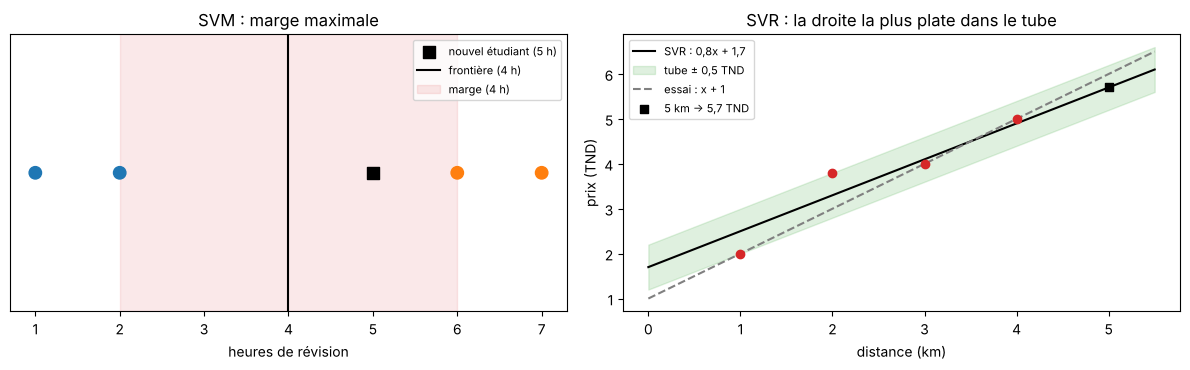

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].scatter(X, [0] * 4, c=["tab:blue" if y < 0 else "tab:orange" for y in Y], s=80, zorder=3)
ax[0].scatter([5], [0], c="k", marker="s", s=70, zorder=3, label="nouvel étudiant (5 h)")
ax[0].axvline(frontiere, color="k", label="frontière (4 h)")
ax[0].axvspan(2, 6, color="tab:red", alpha=0.1, label="marge (4 h)")
ax[0].set_yticks([]); ax[0].set_xlabel("heures de révision"); ax[0].legend(fontsize=8); ax[0].set_title("SVM : marge maximale")
xs = np.linspace(0, 5.5, 50)
ax[1].plot(xs, g(xs), "k", label="SVR : 0,8x + 1,7")
ax[1].fill_between(xs, g(xs) - eps, g(xs) + eps, color="tab:green", alpha=0.15, label="tube ± 0,5 TND")
ax[1].plot(xs, xs + 1, "--", color="gray", label="essai : x + 1")
ax[1].scatter(Xk, Yk, c="tab:red", zorder=3); ax[1].scatter([5], [g(5)], marker="s", c="k", zorder=3, label="5 km → 5,7 TND")
ax[1].set_xlabel("distance (km)"); ax[1].set_ylabel("prix (TND)"); ax[1].legend(fontsize=8); ax[1].set_title("SVR : la droite la plus plate dans le tube")
plt.tight_layout(); plt.show()

## Conclusion


**À retenir**
- Le SVM cherche la frontière avec la **marge la plus large** ; seuls les vecteurs de support comptent.
- Le SVR tolère les erreurs plus petites que ε (le tube) et cherche la droite **la plus plate** possible.
- Les variables doivent être mises à la même échelle (`StandardScaler`) dès qu’il y en a plusieurs.